In [1]:
from keras.datasets import cifar10



I0000 00:00:1792106635.732153   51777 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2842s 17us/step


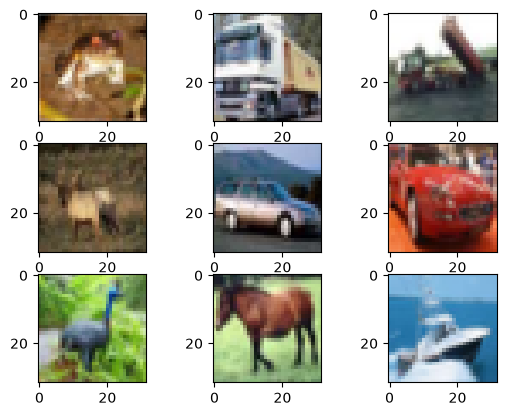

In [3]:
import matplotlib.pyplot as plt

for i in range(9):
    plt.subplot(330 + 1 + i)
    plt.imshow(x_train[i])

plt.show()

In [4]:
from keras.utils import to_categorical

y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

In [5]:
print(y_train[4])

[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]


In [6]:
import numpy as np

np.random.seed(42)

# barajamos el dataset
permutation = np.random.permutation(x_train.shape[0])
x_train = x_train[permutation]
y_train = y_train[permutation]

# obtenemos el conjunto de validación
num_val = 10000
x_val = x_train[:num_val]
x_train = x_train[num_val:]
y_val = y_train[:num_val]
y_train = y_train[num_val:]

In [7]:
from keras import layers
from keras import models

model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='valid', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='valid'))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Flatten())
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))

/home/lerma/Repositorios GitHub/algoritmos-aprendizaje-profundo/entornogpu/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1792166058.637851   51777 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4078 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


In [8]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,204,682 (4.60 MB)

 Trainable params: 1,204,682 (4.60 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
import tensorflow as tf
print("GPUs detectadas: ", tf.config.list_physical_devices('GPU'))

GPUs detectadas:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
from keras import optimizers

model.compile(loss='categorical_crossentropy',
              optimizer=optimizers.SGD(learning_rate=1e-4),
              metrics=['acc'])

train_log = model.fit(x_train, y_train,
                      epochs=10, batch_size=128,
                     validation_data=(x_val, y_val))

Epoch 1/10


I0000 00:00:1792167377.954426   51777 service.cc:154] XLA service 0x23eabc50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792167377.954689   51777 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce GTX 1660 Ti, Compute Capability 7.5 (Driver: 13.2.0[595.97.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792167378.079890   51777 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792167378.533971   51777 cuda_dnn.cc:442] Loaded cuDNN version 92700


 26/313 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - acc: 0.1103 - loss: 14.7083

I0000 00:00:1792167380.749256   51777 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - acc: 0.1973 - loss: 4.6542 - val_acc: 0.2389 - val_loss: 2.7183
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - acc: 0.2584 - loss: 2.4311 - val_acc: 0.2711 - val_loss: 2.2595
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - acc: 0.2894 - loss: 2.1529 - val_acc: 0.2992 - val_loss: 2.0914
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - acc: 0.3113 - loss: 2.0246 - val_acc: 0.3209 - val_loss: 1.9915
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - acc: 0.3286 - loss: 1.9408 - val_acc: 0.3337 - val_loss: 1.9275
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - acc: 0.3460 - loss: 1.8793 - val_acc: 0.3485 - val_loss: 1.8751
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - acc: 0.3595 - loss: 1.8306 - val_acc: 0.3585 - val_loss: 1.8334
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - acc: 0.3706 - loss: 1.7911 - val_acc: 0.3683 - val_loss: 1.7986
Epoch 9/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - acc: 0.3811 

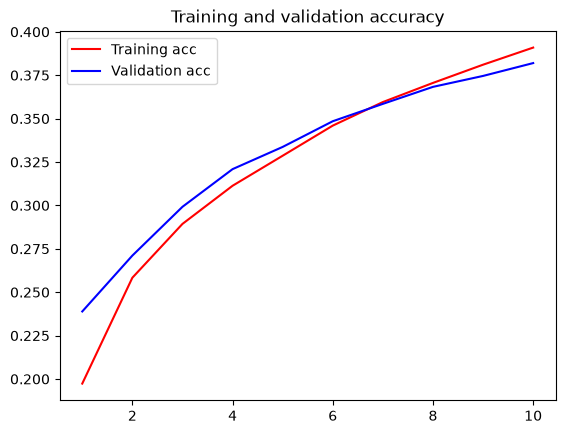

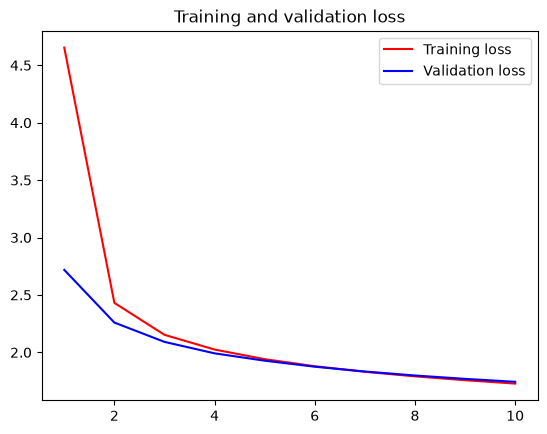

In [12]:
import matplotlib.pyplot as plt

acc = train_log.history['acc']
val_acc = train_log.history['val_acc']
loss = train_log.history['loss']
val_loss = train_log.history['val_loss']
epochs = range(1, len(acc) + 1)
plt.plot(epochs, acc, 'r', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()
plt.plot(epochs, loss, 'r', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()
plt.show()

In [13]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Dropout(0.25))
model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
model.add(layers.Dropout(0.25))
model.add(layers.Flatten())
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(10, activation='softmax'))

In [15]:
model.compile(loss='categorical_crossentropy',
              optimizer=optimizers.RMSprop(learning_rate=1e-4),
              metrics=['acc'])

In [16]:
train_log = model.fit(x_train, y_train,
                      epochs=100, batch_size=128,
                     validation_data=(x_val, y_val))

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - acc: 0.1123 - loss: 6.7059 - val_acc: 0.1679 - val_loss: 2.2480
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - acc: 0.1374 - loss: 2.2756 - val_acc: 0.1842 - val_loss: 2.1847
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - acc: 0.1580 - loss: 2.2130 - val_acc: 0.2113 - val_loss: 2.0859
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - acc: 0.1907 - loss: 2.1206 - val_acc: 0.2651 - val_loss: 1.9813
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - acc: 0.2285 - loss: 2.0268 - val_acc: 0.3088 - val_loss: 1.8414
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - acc: 0.2625 - loss: 1.9422 - val_acc: 0.3623 - val_loss: 1.7522
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - acc: 0.2981 - loss: 1.8583 - val_acc: 0.4047 - val_loss: 1.6767
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - acc: 0.3221 - loss: 1.7972 - val_acc: 0.4236 - val_loss: 1.6273
Epoch 9/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9m

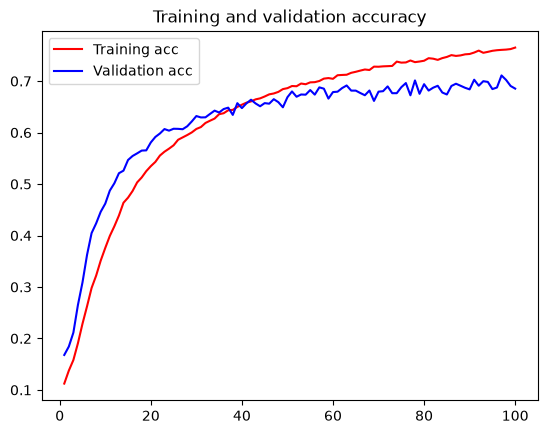

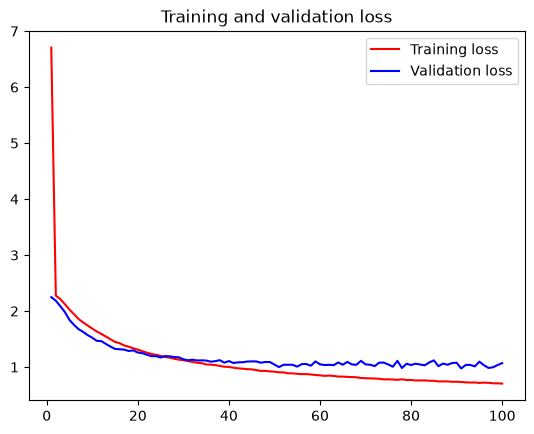

In [17]:
import matplotlib.pyplot as plt

acc = train_log.history['acc']
val_acc = train_log.history['val_acc']
loss = train_log.history['loss']
val_loss = train_log.history['val_loss']
epochs = range(1, len(acc) + 1)
plt.plot(epochs, acc, 'r', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()
plt.plot(epochs, loss, 'r', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()
plt.show()